
# 03 会计、税务与业绩归因：把“交易赚钱”变成“公司赚钱”

> **本章要解决的问题**：账户里赚了 10 万，公司到底赚了多少？哪一部分是策略赚的、哪一部分被手续费和滑点吃掉了？年底要交多少税，报表上的利润和账户权益为什么对不上？

## 本章导读

交易账户只告诉你“钱变多了”，公司经营要回答四个问题：**赚了多少、从哪来、被什么吃掉、什么时候交税**。这四件事分别对应：三本账、费用分类、业绩归因、税务口径。

本章按下面的顺序展开：

1. **三本账**：交易账、资金账、权益账，先保证账对得上；
2. **费用**：显性费用（佣金、交易所费、印花税）与隐性成本（价差、滑点、资金成本）；
3. **税**：只讲口径与示例，不讲“怎么避税”；
4. **业绩归因**：按策略、按品种、按成本拆解；
5. **对账与留痕**：月度检查清单。

> **声明**：本章所有税率、费率和申报口径均为**教学示例，非专业意见**。真实申报请以现行税法、交易所规则和税务师意见为准。

### 学习目标

- 给定一份逐笔成交记录，能建出交易账，并算出每笔的毛利、费用和净利。
- 给定显性费用与隐性成本，能把“毛利”拆到“公司净利”，并算成本拖累比例。
- 给定税前利润与适用税率（教学示例），能估算税后利润，并说清毛利/税前/税后三种口径的差别。
- 给定多策略、多品种的交易账，能做出按策略和按品种的归因表，并解释差异来源。
- 给定账本权益与券商对账单，能定位常见对账差异（漏记、重复、费用错、跨期）。
- 能写出一份包含“收益、回撤、成本、税、归因”的月度经营报表要素清单。

### 先修

第 01 章（主体与成本）、第 21 章（收益归因与增量价值）、第 22 章（订单容量与可实现收益）；会 pandas 的分组与透视。

## 在量化研究中的位置

- **谁用**：一人公司创始人、运营/财务、资金方、审计与税务顾问。
- **输入**：逐笔成交、出入金记录、费用单据、券商对账单、税率与申报口径。
- **输出**：交易账、资金账、权益账、费用表、税估算、归因表、月度经营报表。
- **在流程的哪一步**：在“交易执行”之后、“分配利润/申报纳税”之前；它把交易结果翻译成经营结果。
- **失败模式**：只记交易不记费用、把浮盈当利润、税估算口径混用、归因只看总收益不看成本。
- **最小工作流**：逐笔记账 → 算费用 → 算税 → 做归因 → 对账 → 出报表。

### 环境准备



In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
pd.set_option("display.width", 140)
print("numpy", np.__version__, "| pandas", pd.__version__)
print("本章税率与费率均为教学示例，非专业意见")


numpy 2.4.4 | pandas 3.0.2
本章税率与费率均为教学示例，非专业意见



## 1. 三本账：交易账、资金账、权益账

### 1.1 交易账

交易账是一笔一笔的成交/平仓记录，每条至少包含：时间、策略、品种、方向、开平、成交价、数量、合约乘数、手续费。它是所有后续计算的“原始凭证”。

### 1.2 资金账

资金账记录钱的进出：入金、出金、手续费、税费、利息、分红。它回答“账户里现金是怎么变的”，和交易账是两套数，必须能对上。

### 1.3 权益账

权益账是每日快照：权益 = 现金 + 持仓市值 − 负债。**利润不是“账户里多了多少钱”，而是权益的跨期变化扣除出入金**。这一点搞错，归因就全错。

### 1.4 先建一本逐笔账

下面构造 10 笔已平仓交易（教学示例），覆盖股票、期货、期权三类，策略分 A/B/C 三组。



In [2]:

trades = pd.DataFrame(
    [
        ("2024-01-05", "A 反转", "600519", "股票", 1, 1600.0, 1650.0, 100, 1, 5.0),
        ("2024-01-12", "A 反转", "rb2405", "期货", 1, 3900.0, 3960.0, 5, 10, 30.0),
        ("2024-01-19", "A 反转", "m2405", "期货", -1, 3100.0, 3060.0, 4, 10, 24.0),
        ("2024-02-02", "A 反转", "rb2405", "期货", -1, 4000.0, 3985.0, 3, 10, 18.0),
        ("2024-02-08", "B 趋势", "IF2402", "期货", 1, 3300.0, 3350.0, 1, 300, 30.0),
        ("2024-02-23", "B 趋势", "au2406", "期货", 1, 480.0, 492.0, 2, 1000, 40.0),
        ("2024-03-01", "B 趋势", "cu2403", "期货", 1, 68000.0, 68800.0, 1, 5, 25.0),
        ("2024-03-08", "C 卖方", "m2405-C-3100", "期权", -1, 45.0, 15.0, 3, 10, 30.0),
        ("2024-03-15", "C 卖方", "rb2405-C-4000", "期权", -1, 30.0, 8.0, 2, 10, 20.0),
        ("2024-03-22", "C 卖方", "IF2402-P-3300", "期权", -1, 20.0, 35.0, 1, 300, 30.0),
    ],
    columns=["平仓日", "策略", "品种", "类别", "方向", "开仓价", "平仓价", "手数", "乘数", "手续费"],
)
trades["毛利"] = (trades["平仓价"] - trades["开仓价"]) * trades["方向"] * trades["手数"] * trades["乘数"]
print(trades.to_string(index=False))
print("毛利合计:", trades["毛利"].sum(), "元")


       平仓日   策略            品种 类别  方向     开仓价     平仓价  手数   乘数  手续费      毛利
2024-01-05 A 反转        600519 股票   1  1600.0  1650.0 100    1  5.0  5000.0
2024-01-12 A 反转        rb2405 期货   1  3900.0  3960.0   5   10 30.0  3000.0
2024-01-19 A 反转         m2405 期货  -1  3100.0  3060.0   4   10 24.0  1600.0
2024-02-02 A 反转        rb2405 期货  -1  4000.0  3985.0   3   10 18.0   450.0
2024-02-08 B 趋势        IF2402 期货   1  3300.0  3350.0   1  300 30.0 15000.0
2024-02-23 B 趋势        au2406 期货   1   480.0   492.0   2 1000 40.0 24000.0
2024-03-01 B 趋势        cu2403 期货   1 68000.0 68800.0   1    5 25.0  4000.0
2024-03-08 C 卖方  m2405-C-3100 期权  -1    45.0    15.0   3   10 30.0   900.0
2024-03-15 C 卖方 rb2405-C-4000 期权  -1    30.0     8.0   2   10 20.0   440.0
2024-03-22 C 卖方 IF2402-P-3300 期权  -1    20.0    35.0   1  300 30.0 -4500.0
毛利合计: 49890.0 元



**读数与应用**：10 笔交易毛利合计 49,890 元，其中 IF 期权卖方一笔亏 4,500 元，是最大的单笔亏损。**逐笔账的价值是“每笔可解释”**，而不是只有一个总数。常见错误：只记平仓不记开仓、不同品种的乘数混用、把期权权利金按股票价格口径记。

### 1.5 权责发生制与收付实现制

记账有两种时点：

- **收付实现制**：钱到账才记收入，钱付出才记费用；
- **权责发生制**：交易发生的当期就记收入/费用，不管钱是否到账。

交易账通常按成交日归属（权责发生制），资金账按到账日归属（收付实现制）。两本账天然会有时间差：月末最后一天成交、下月才结算，就会出现“交易账盈利、资金账没变”。**这不是错账，而是口径差异，但要在报表里说明。**

## 2. 费用：显性与隐性

### 2.1 显性费用

显性费用是能从对账单上直接看到的支出：佣金、交易所手续费、印花税、过户费，以及数据费、软件费、托管费。它们有单据、可核对。

### 2.2 隐性成本

隐性成本是“没写在账单上但真实发生”的损失：买卖价差、滑点、冲击成本、资金成本。它们只能估算，但往往比显性费用更大。

### 2.3 公式与口径

单笔净利：

$$\text{净利}=\text{毛利}-\text{显性费用}-\text{隐性成本}.$$

成本拖累：

$$\text{成本拖累}=\frac{\text{显性费用}+\text{隐性成本}}{\text{毛利}}.$$

毛利为负时，这个比例没有意义，要单独看“亏损是被市场还是被成本放大的”。



In [3]:

# 显性费用：手续费；股票卖出另计印花税（教学示例 0.05%）
stamp = np.where(
    (trades["类别"] == "股票") & (trades["方向"] > 0),
    trades["平仓价"] * trades["手数"] * trades["乘数"] * 0.0005,
    0.0,
)
# 隐性成本：假设每边滑点 0.5 个最小变动单位（教学示例）
slip_points = 0.5
slip = slip_points * 2 * trades["手数"] * trades["乘数"]

trades["印花税"] = stamp
trades["滑点成本"] = slip
trades["净利"] = trades["毛利"] - trades["手续费"] - trades["印花税"] - trades["滑点成本"]
print(trades[["策略", "品种", "毛利", "手续费", "印花税", "滑点成本", "净利"]].to_string(index=False))
print("合计 毛利 %.0f｜显性 %.0f｜滑点 %.0f｜净利 %.0f" % (
    trades["毛利"].sum(), trades["手续费"].sum(), trades["滑点成本"].sum(), trades["净利"].sum()))
cost_drag = (trades["手续费"].sum() + trades["印花税"].sum() + trades["滑点成本"].sum()) / trades["毛利"].sum()
print("成本拖累（成本/毛利）:", round(cost_drag * 100, 2), "%")


  策略            品种      毛利  手续费  印花税   滑点成本      净利
A 反转        600519  5000.0  5.0 82.5  100.0  4812.5
A 反转        rb2405  3000.0 30.0  0.0   50.0  2920.0
A 反转         m2405  1600.0 24.0  0.0   40.0  1536.0
A 反转        rb2405   450.0 18.0  0.0   30.0   402.0
B 趋势        IF2402 15000.0 30.0  0.0  300.0 14670.0
B 趋势        au2406 24000.0 40.0  0.0 2000.0 21960.0
B 趋势        cu2403  4000.0 25.0  0.0    5.0  3970.0
C 卖方  m2405-C-3100   900.0 30.0  0.0   30.0   840.0
C 卖方 rb2405-C-4000   440.0 20.0  0.0   20.0   400.0
C 卖方 IF2402-P-3300 -4500.0 30.0  0.0  300.0 -4830.0
合计 毛利 49890｜显性 252｜滑点 2875｜净利 46680
成本拖累（成本/毛利）: 6.43 %



**读数与应用**：毛利 49,890 元，扣掉手续费 252 元、印花税 82.5 元、滑点 2,875 元后净利 46,680 元，成本拖累 6.43%。**滑点是最容易被忽略的一项**：0.5 个点的假设变化，就能让净利差出几千元。常见错误：只算手续费、按理想成交价回测、把数据费/软件费漏在经营成本之外。

### 2.4 成本的三种估算方法

隐性成本没有现成单据，常用三种估算：

1. **价差法**：用买卖价差的一半乘以成交金额；
2. **滑点法**：用“预期成交价 − 实际成交价”乘数量；
3. **冲击模型**：按成交量占市场成交的比例估算冲击成本。

教学阶段用前两种即可；实盘规模变大后，冲击成本会成为主导项，必须用逐笔成交数据回测。

再补一句：隐性成本的估算值要和券商对账单交叉验证。如果你的滑点估算长期低于对账单上的“成交价差”，说明模型低估了执行难度，回测收益要往下修。

## 3. 税：先把口径分开

### 3.1 三种口径

同一年，你会看到三个“利润”：

| 口径 | 含义 | 常见用途 |
|---|---|---|
| 毛利 | 交易价差，不扣任何费用 | 评估策略本身 |
| 税前利润 | 毛利 − 费用 − 经营成本 | 经营分析、估算税 |
| 税后利润 | 税前利润 − 所得税 | 可分配利润、复利基准 |

把三个口径混用，是“报表和账户对不上”的最常见原因。

### 3.2 常见税种（概念，非专业意见）

- 印花税：A 股卖出时按成交金额征收（教学示例 0.05%，以现行规定为准）；
- 所得税：企业有所得税、个人有所得税，口径不同；
- 增值税：金融商品交易的适用规则复杂，是否征收、如何计算需按现行规定与专业意见判断。

本节只做“估算演示”，不构成税务建议。

### 3.3 税估算



In [4]:

tax_rate = 0.25  # 教学示例：企业所得税率，非专业意见
pre_tax = trades["净利"].sum() - 30_000  # 再扣年度经营成本（数据/软件/记账，示例）
if pre_tax > 0:
    income_tax = pre_tax * tax_rate
else:
    income_tax = 0.0
after_tax = pre_tax - income_tax
print("毛利合计:", round(trades["毛利"].sum(), 2))
print("净利（已扣交易费用）:", round(trades["净利"].sum(), 2))
print("税前利润（再扣经营成本 30000）:", round(pre_tax, 2))
print("所得税估算:", round(income_tax, 2), "| 税后利润:", round(after_tax, 2))
print("有效税率（税/税前）:", round(income_tax / pre_tax * 100, 2) if pre_tax > 0 else "不适用", "%")


毛利合计: 49890.0
净利（已扣交易费用）: 46680.5
税前利润（再扣经营成本 30000）: 16680.5
所得税估算: 4170.12 | 税后利润: 12510.38
有效税率（税/税前）: 25.0 %



**读数与应用**：交易净利 46,680 元，扣 3 万经营成本后税前利润 16,680 元，按 25% 估算所得税约 4,170 元，税后约 12,510 元。**注意“交易净利”不等于“公司利润”**：数据费、软件费、记账费都要扣。常见错误：用毛利直接乘税率、忘记经营成本、把不同税种的计税基础混在一起。

### 3.4 税的口径与时间

估算税时最容易错的是“时间”和“口径”：

- 时间：所得税通常按年度汇算，季度只是预缴；用单月利润乘税率会低估或高估；
- 口径：亏损能否结转、不同品种是否分开计税、费用是否有扣除限额，都要按现行规定；
- 凭证：发票、成交单、费用单据要留档，否则“算得对”也可能“报不了”。

再次强调：以上只是教学示例，**不构成税务意见**；真实申报请找税务师确认。

## 4. 业绩归因：钱从哪来

### 4.1 按策略归因

按策略汇总毛利、费用、净利，看每个策略贡献多少。归因不是“分功劳”，而是回答“哪个策略值得继续投钱”。

### 4.2 按品种归因

按品种看，同一策略在不同品种上的成本结构可能完全不同：股指期货一手乘数 300，滑点成本远高于农产品。

### 4.3 成本瀑布

把“毛利 → 手续费 → 印花税 → 滑点 → 净利”画成瀑布，一眼看出钱被谁吃掉。



In [5]:

by_strategy = trades.groupby("策略").agg(
    笔数=("净利", "size"), 毛利=("毛利", "sum"), 费用=("手续费", "sum"),
    滑点=("滑点成本", "sum"), 净利=("净利", "sum")).reset_index()
by_strategy["净利率%"] = np.where(
    by_strategy["毛利"] > 0,
    (by_strategy["净利"] / by_strategy["毛利"] * 100).round(2),
    np.nan,
)
by_strategy["净利占比%"] = (by_strategy["净利"] / by_strategy["净利"].sum() * 100).round(2)
print(by_strategy.to_string(index=False))

by_symbol = trades.groupby("品种").agg(
    笔数=("净利", "size"), 毛利=("毛利", "sum"), 净利=("净利", "sum")).reset_index()
by_symbol["成本占毛利%"] = ((by_symbol["毛利"] - by_symbol["净利"]) / by_symbol["毛利"] * 100).round(2)
print()
print(by_symbol.sort_values("净利", ascending=False).to_string(index=False))


  策略  笔数      毛利   费用     滑点      净利  净利率%  净利占比%
A 反转   4 10050.0 77.0  220.0  9670.5 96.22  20.72
B 趋势   3 43000.0 95.0 2305.0 40600.0 94.42  86.97
C 卖方   3 -3160.0 80.0  350.0 -3590.0   NaN  -7.69

           品种  笔数      毛利      净利  成本占毛利%
       au2406   1 24000.0 21960.0    8.50
       IF2402   1 15000.0 14670.0    2.20
       600519   1  5000.0  4812.5    3.75
       cu2403   1  4000.0  3970.0    0.75
       rb2405   2  3450.0  3322.0    3.71
        m2405   1  1600.0  1536.0    4.00
 m2405-C-3100   1   900.0   840.0    6.67
rb2405-C-4000   1   440.0   400.0    9.09
IF2402-P-3300   1 -4500.0 -4830.0   -7.33



**读数与应用**：B 趋势贡献净利 40,600 元（占 87%），A 反转 9,670 元，C 卖方 -3,590 元被一笔 IF 期权亏损拖累；按品种看，au 的单笔成本占毛利 8.5% 最高。**归因必须把“费用”和“滑点”分开**，否则你不知道该换券商还是该改执行。常见错误：只按策略汇总不按品种、用占比代替金额、把某笔极端亏损归因成“运气”。

### 4.4 归因的两种口径：逐笔 vs 时间加权

按逐笔归因简单，但会被“资金占用时间”扭曲：一笔持有 1 天的交易和一笔持有 3 个月、占用大量资金的交易，按金额加总会高估前者。

更严谨的做法是时间加权：把每笔交易的盈亏按占用资金和天数折算成年化贡献。教学阶段先用逐笔口径，等资金规模变大、多策略并行时，再升级到时间加权。**口径没有绝对对错，但要在报表里写清楚用的是哪一种。**

## 5. 对账、报表与留痕

### 5.1 月度对账清单

对账就是把“你的账”和“券商/银行的对账单”对上。差异通常来自四类：漏记（少记一笔）、重复（同一笔记两次）、口径错（乘数、方向、费用）、跨期（成交在月末、费用在下月）。

### 5.2 常见差错

1. 手续费按“元/手”与“成交额比例”混记；
2. 期权卖方把保证金当成本；
3. 股票分红、利息没进资金账；
4. 跨月平仓只记了平仓日、没记开仓日，导致月度归属错。

### 5.3 月度经营报表

一张可交付的月报至少包含：期初期末权益、当月净利、最大回撤、费用明细、税估算、按策略归因、下月计划。对外展示时还要写清“历史业绩不代表未来、口径与费用处理方式”。



     月份      毛利    费用     滑点      净利    累计净利    初始权益      期末权益  月收益率%
2024-01  9600.0  59.0  190.0  9268.5  9268.5 1000000 1009268.5  0.927
2024-02 39450.0  88.0 2330.0 37032.0 46300.5 1000000 1046300.5  3.669
2024-03   840.0 105.0  355.0   380.0 46680.5 1000000 1046680.5  0.036


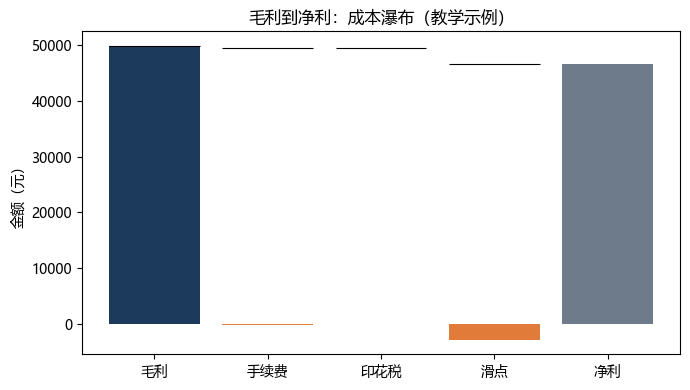

In [6]:

trades["平仓日"] = pd.to_datetime(trades["平仓日"])
trades["月份"] = trades["平仓日"].dt.to_period("M").astype(str)
monthly = trades.groupby("月份").agg(
    毛利=("毛利", "sum"), 费用=("手续费", "sum"), 滑点=("滑点成本", "sum"), 净利=("净利", "sum")).reset_index()
monthly["累计净利"] = monthly["净利"].cumsum()
monthly["初始权益"] = 1_000_000
monthly["期末权益"] = monthly["初始权益"] + monthly["累计净利"]
monthly["月收益率%"] = (monthly["净利"] / (monthly["初始权益"] + monthly["累计净利"] - monthly["净利"]) * 100).round(3)
print(monthly.to_string(index=False))

waterfall = [
    ("毛利", trades["毛利"].sum()),
    ("手续费", -trades["手续费"].sum()),
    ("印花税", -trades["印花税"].sum()),
    ("滑点", -trades["滑点成本"].sum()),
]
labels = [x[0] for x in waterfall] + ["净利"]
values = [x[1] for x in waterfall]
running = np.cumsum(values)
plt.figure(figsize=(7, 4))
plt.bar(labels[:-1], values, color=["#1B3A5C", "#E07B39", "#E07B39", "#E07B39"])
plt.bar(["净利"], [trades["净利"].sum()], color="#6E7B8B")
for i, b in enumerate(running):
    plt.hlines(b, i - 0.4, i + 0.4, color="black", linewidth=0.8)
plt.title("毛利到净利：成本瀑布（教学示例）")
plt.ylabel("金额（元）")
plt.tight_layout()
plt.show()



**读数与应用**：月度表显示 1 月净利 9,269 元、2 月 37,032 元，3 月因 IF 期权亏损 4,830 元回落到 380 元；瀑布图把毛利到净利的每一步画出来。**报表的价值是让“下个月怎么改”有依据**：是数据费太高、还是滑点太大、还是某个策略该停。常见错误：月报只有收益率没有成本、不写口径、把浮盈算进已实现利润。

### 5.4 报表口径说明模板

对外展示业绩时，至少写清五件事：

1. 统计区间与币种；
2. 收益口径（时间加权/资金加权、是否扣费、是否含税）；
3. 费用处理方式（是否含数据费、软件费）；
4. 回撤与波动的计算方法；
5. “历史业绩不代表未来”的风险提示。

写清口径不是形式主义：同一策略按不同口径算，年化收益可能差好几个百分点。

### 5.5 一页纸月度检查表

每月固定花半小时，按下面五项过一遍：

1. 账本权益与券商对账单是否一致（差异≤千分之一）；
2. 费用率是否在预算内（佣金、滑点、数据费分项看）；
3. 归因表里有没有异常单笔（贡献超过总利润一半的交易要复盘）；
4. 税估算是否按最新利润更新、凭证是否齐全；
5. 下月资金计划与风险限额是否明确。

这五项都能回答“是”，这个月的账才算真的结清。

## 本章小结

### 一张表

| 环节 | 关键动作 | 常见坑 |
|---|---|---|
| 交易账 | 逐笔记方向/价格/手数/乘数/费用 | 漏开仓、乘数混用 |
| 资金账 | 出入金、费用、税、利息 | 把权益变化当利润 |
| 费用 | 显性 + 隐性分开 | 只算佣金不算滑点 |
| 税 | 毛利/税前/税后三种口径 | 口径混用 |
| 归因 | 按策略、按品种、按成本 | 只看总收益 |
| 对账 | 与券商/银行对账单核对 | 跨期归属错 |

### 八句话

1. 交易赚钱不等于公司赚钱。
2. 三条账要能互相对上。
3. 显性费用有单据，隐性成本靠估算。
4. 成本拖累 = 成本 / 毛利。
5. 毛利、税前、税后三种口径不能混。
6. 归因要按策略和品种分开看。
7. 对账差异通常来自漏记、重复、口径、跨期。
8. 本章参数都是教学示例，申报找专业人士。

## 本章习题

**1.** 交易账、资金账、权益账各自回答什么问题？

**2.** 毛利 10 万元，手续费 3,000 元、印花税 500 元、滑点 4,500 元，净利是多少？成本拖累是多少？

**3.** 为什么“交易净利”不等于“公司税前利润”？

**4.** 期权卖方交的保证金，应该记成费用还是资产占用？

**5.** 按策略归因时，除了净利还应该看哪两个指标？

**6.** 对账差异最常见的四类原因是什么？

**7.** 为什么要区分“已实现盈亏”和“浮动盈亏”？

**8.** 一份月度经营报表至少包含哪些要素？

<details><summary>参考答案</summary>

**1.** 交易账回答“每笔赚亏多少”；资金账回答“现金怎么进出”；权益账回答“某一时点账户值多少”。

**2.** 净利 = 100000 − 3000 − 500 − 4500 = 92,000 元；成本拖累 = 8000/100000 = 8%。

**3.** 交易净利只扣交易相关费用；公司税前利润还要扣数据费、软件费、记账费、房租等经营成本。

**4.** 资产占用（或保证金占用），不是费用；它影响可用资金和强平风险，但不直接进损益。

**5.** 费用（含滑点）与净利率/净利占比；只看净利会忽略“这个策略是靠高成本换来的”。

**6.** 漏记、重复记账、口径错误（乘数/方向/费用）、跨期归属。

**7.** 已实现盈亏才是可用于分配和纳税的基础；浮动盈亏会随行情反转，不能当现金。

**8.** 期初期末权益、当月净利、最大回撤、费用明细、税估算、按策略/品种归因、口径说明与下月计划。

</details>

---

## 参考资料

- Hull, J. C. *Options, Futures, and Other Derivatives*（交易与结算基础）。
- 中国证监会、交易所关于交易费用与结算的公开规则（以最新发布为准）。
- 第 01 章（主体与成本）、第 21 章（收益归因）、第 22 章（订单容量与可实现收益）。
